# Notebook 04 — Text / NLP, Shipping Network Graph & Association Rules



This notebook covers three major analytics tasks on the Olist e-commerce dataset:

All data is read from `PROCESSED_DATA/` (generated by Notebook 01).

---
##  Setup & Imports

In [1]:
# ── Standard libraries ──────────────────────────────────────────────
import os
import re
import string
import unicodedata
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

# Compatibility patch for pandas versions where format_name was refactored
try:
    import pandas.io.formats.format as _pff
    if not hasattr(_pff, 'format_name'):
        _pff.format_name = lambda name: str(name) if name is not None else ""
except Exception:
    pass

# ── Visualization ───────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# ── NLP / Text (Lecture 9) ──────────────────────────────────────────
from sklearn.feature_extraction.text import TfidfVectorizer

# ── Graph Analysis (Lecture 10) ─────────────────────────────────────
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities

# ── Association Rules (Lecture 18) ──────────────────────────────────
try:
    from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
    from mlxtend.preprocessing import TransactionEncoder
except ImportError:
    pass

print('All imports successful ✓')

All imports successful ✓


###   Load Processed Data

We load four CSV files from `PROCESSED_DATA/`:
- **`master_orders.csv`** — 1 row per order with delivery metrics, review scores, seller/customer states, lateness buckets.
- **`cleaned_reviews.csv`** — De-duplicated reviews with `has_comment` flag.
- **`cleaned_items.csv`** — Order-item level data with English category names.
- **`master_sellers.csv`** — 1 row per seller with aggregated performance metrics.

In [5]:
# ── Path to processed data ──────────────────────────────────────────
DATA_DIR = r'C:\Users\nandu\Downloads\DELTA\PROCESSED_DATA'
# ── Load datasets ───────────────────────────────────────────────────
orders = pd.read_csv(os.path.join(DATA_DIR, 'master_orders.csv'))
reviews = pd.read_csv(os.path.join(DATA_DIR, 'cleaned_reviews.csv'))
items = pd.read_csv(os.path.join(DATA_DIR, 'cleaned_items.csv'))
sellers = pd.read_csv(os.path.join(DATA_DIR, 'master_sellers.csv'))

print(f'master_orders: {orders.shape[0]:,} rows × {orders.shape[1]} cols')
print(f'cleaned_reviews: {reviews.shape[0]:,} rows × {reviews.shape[1]} cols')
print(f'cleaned_items: {items.shape[0]:,} rows × {items.shape[1]} cols')
print(f'master_sellers: {sellers.shape[0]:,} rows × {sellers.shape[1]} cols')

master_orders: 99,441 rows × 59 cols
cleaned_reviews: 98,673 rows × 7 cols
cleaned_items: 112,650 rows × 10 cols
master_sellers: 3,095 rows × 25 cols


In [6]:
# Quick peek at the reviews table (our main input for Section A)
reviews.head(3)

,order_id,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,has_comment
0,bd2c2c3a4d59e68fb14a526745572883,0574e3efaf2a10ee2d0c45b1ed544c84,4,NaN,NaN,2018-08-31 00:00:00,0
1,529a65336debb1c3e3327d7d67dc733d,f542d0ff698f5272fbd13deca2349582,5,Excelente,NaN,2018-08-31 00:00:00,0
2,b0e9288a209f5ec50391c140dba4c91f,02d00568beb770ce3939f4fca60556a1,5,NaN,NaN,2018-08-31 00:00:00,0


In [7]:
# Quick peek at the orders table (used for graph & rules)
orders[['order_id', 'seller_state', 'customer_state',
         'days_late', 'is_late', 'lateness_bucket', 'review_score']].head(3)

,order_id,seller_state,customer_state,days_late,is_late,lateness_bucket,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,SP,-7.107488,0.0,Early (>1d early),4.0
1,53cdb2fc8bc7dce0b6741e2150273451,SP,BA,-5.355729,0.0,Early (>1d early),4.0
2,47770eb9100c2d0c44946d9cf07ec65d,SP,GO,-17.245498,0.0,Early (>1d early),5.0


In [8]:
# Check how many reviews actually have text comments
n_total   = len(reviews)
n_comment = int(reviews['has_comment'].sum())
pct       = n_comment / n_total * 100
print(f'Reviews with text: {n_comment:,} / {n_total:,}  ({pct:.1f}%)')
print(f'Reviews without text: {n_total - n_comment:,}  ({100 - pct:.1f}%)')

Reviews with text: 40,774 / 98,673  (41.3%)
Reviews without text: 57,899  (58.7%)


---
# Section A — Text Analytics on Portuguese Reviews (Lecture 9)

**Goal:** Extract the most common complaints from customer reviews written in Portuguese, and compare the language used in **1-star vs 5-star** reviews and **late vs on-time** deliveries.

**Steps:**
1. Merge review text with delivery lateness info from `master_orders`.
2. Clean the Portuguese text (lowercase, strip accents, remove punctuation/numbers/stopwords — but **keep negation words** like `não`, `nunca`, `sem`).
3. Build unigram + bigram TF-IDF features.
4. Rank and visualize the top terms for each review group.

## A.1  Prepare Review Text with Lateness Labels

In [9]:
# Merge reviews with lateness info from master_orders
# We only need a few columns from orders for this section
review_text = reviews.merge(
    orders[['order_id', 'is_late', 'lateness_bucket', 'days_late']],
    on='order_id',
    how='left'
)

# Keep only rows that actually have a written comment
review_text = review_text[review_text['has_comment'] == 1].copy()
review_text = review_text.dropna(subset=['review_comment_message'])

print(f'Reviews with text after merge: {len(review_text):,}')
print()
print('Score distribution of reviews WITH comments:')
print(review_text['review_score'].value_counts().sort_index())

Reviews with text after merge: 40,774

Score distribution of reviews WITH comments:
review_score
1     8706
2     2132
3     3537
4     5950
5    20449
Name: count, dtype: int64


In [10]:
# Show a few raw comment examples
print('=== Sample 1-star review ===')
sample_1 = review_text[review_text['review_score'] == 1]['review_comment_message'].iloc[0]
print(sample_1)
print()
print('=== Sample 5-star review ===')
sample_5 = review_text[review_text['review_score'] == 5]['review_comment_message'].iloc[0]
print(sample_5)

=== Sample 1-star review ===
Peço um produto por um código e vem outro totalmente diferente.

=== Sample 5-star review ===
Chegou antes do prazo. Obrigado.


## A.2  Portuguese Text Cleaning

Standard NLP stopword lists for Portuguese remove words like **`não`** (not), **`nunca`** (never), **`nem`** (nor), **`sem`** (without). But these are **negation words** that completely change the meaning of a sentence:

- `"não recebi"` → *"did not receive"*  
- `"recebi"` → *"received"*

If we strip negations, angry complaints look identical to positive comments. So we **keep negation words** and only remove neutral stopwords (prepositions, articles, conjunctions).

In [11]:
# ── Portuguese stopword list (manually curated) ─────────────────────
# Common Portuguese stopwords EXCLUDING negation words
PT_STOPWORDS = {
    # Articles
    'o', 'a', 'os', 'as', 'um', 'uma', 'uns', 'umas',
    # Prepositions
    'de', 'do', 'da', 'dos', 'das', 'em', 'no', 'na', 'nos', 'nas',
    'por', 'pelo', 'pela', 'pelos', 'pelas', 'com', 'para', 'ao', 'aos',
    'entre', 'ate', 'sobre', 'apos',
    # Conjunctions
    'e', 'ou', 'mas', 'porem', 'que', 'se', 'como', 'quando', 'porque',
    'pois', 'ja', 'ainda', 'tambem', 'entao', 'assim', 'logo',
    # Pronouns (non-negation)
    'eu', 'tu', 'ele', 'ela', 'nos', 'eles', 'elas', 'voce', 'voces',
    'me', 'te', 'se', 'lhe', 'lhes', 'mim', 'ti', 'si',
    'meu', 'minha', 'meus', 'minhas', 'teu', 'tua', 'teus', 'tuas',
    'seu', 'sua', 'seus', 'suas', 'nosso', 'nossa', 'nossos', 'nossas',
    'este', 'esta', 'estes', 'estas', 'esse', 'essa', 'esses', 'essas',
    'aquele', 'aquela', 'aqueles', 'aquelas', 'isto', 'isso', 'aquilo',
    # Common verbs (auxiliary / copular)
    'ser', 'estar', 'ter', 'haver', 'ir', 'foi', 'era', 'sao',
    'esta', 'estou', 'tem', 'tinha', 'vai', 'vou',
    'fui', 'foram', 'seria', 'seria', 'sendo', 'sido', 'tendo',
    # Other high-frequency neutral words
    'mais', 'muito', 'muita', 'muitos', 'muitas', 'so', 'mesmo',
    'mesma', 'mesmos', 'mesmas', 'outro', 'outra', 'outros', 'outras',
    'cada', 'todo', 'toda', 'todos', 'todas', 'qual', 'quais',
    'onde', 'quem', 'quanto', 'quanta', 'quantos', 'quantas',
    'la', 'ca', 'aqui', 'ali', 'ai', 'alem', 'bem', 'depois',
    'antes', 'agora', 'sempre', 'vezes', 'vez', 'coisa', 'coisas',
    'dia', 'dias', 'fazer', 'feito', 'fez', 'pode', 'poder',
    'deve', 'dever', 'parte', 'partes'
}

# ── Negation words we intentionally KEEP ───────────────────────────
NEGATION_WORDS = {'nao', 'nunca', 'nem', 'sem', 'jamais', 'nenhum',
                  'nenhuma', 'nada', 'tampouco'}

print(f'Stopwords: {len(PT_STOPWORDS)} words (negations excluded)')
print(f'Negation words kept: {NEGATION_WORDS}')

Stopwords: 165 words (negations excluded)
Negation words kept: {'nenhuma', 'nenhum', 'nem', 'sem', 'tampouco', 'nada', 'nao', 'nunca', 'jamais'}


In [12]:
def clean_portuguese(text):
    """
    Clean a Portuguese review comment:
    1. Lowercase
    2. Normalize unicode (strip accents: ã→a, ç→c, é→e)
    3. Remove punctuation and numbers
    4. Remove stopwords (but KEEP negation words)
    5. Remove single-character tokens
    """
    if not isinstance(text, str):
        return ''
    
    # Step 1: lowercase
    text = text.lower()
    
    # Step 2: strip accents  (NFD decomposes ã into a + combining tilde,
    #          then we drop the combining characters)
    text = unicodedata.normalize('NFD', text)
    text = ''.join(c for c in text if unicodedata.category(c) != 'Mn')
    
    # Step 3: remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)
    
    # Step 4: tokenize, remove stopwords (keep negations), remove short tokens
    tokens = text.split()
    tokens = [t for t in tokens if len(t) > 1 and t not in PT_STOPWORDS]
    
    return ' '.join(tokens)


# ── Apply cleaning ──────────────────────────────────────────────────
review_text['clean_text'] = review_text['review_comment_message'].apply(clean_portuguese)

# Drop rows where cleaning produced empty strings
review_text = review_text[review_text['clean_text'].str.strip().astype(bool)].copy()

print(f'Reviews after cleaning: {len(review_text):,}')
print()
print('--- Before cleaning ---')
print(review_text['review_comment_message'].iloc[0])
print()
print('--- After cleaning ---')
print(review_text['clean_text'].iloc[0])

Reviews after cleaning: 40,556

--- Before cleaning ---
Chegou antes do prazo. Obrigado.

--- After cleaning ---
chegou prazo obrigado


## A.3  TF-IDF Feature Extraction (Unigrams + Bigrams)

**TF-IDF** (Term Frequency – Inverse Document Frequency) scores each word/phrase by:
- **TF:** How often it appears in one document (review).
- **IDF:** How rare it is across all documents. Common words get low IDF; distinctive words get high IDF.

We extract both **unigrams** (single words) and **bigrams** (two-word phrases like `nao recebi` or `produto chegou`) so we can capture negation patterns.

In [13]:
# ── Build TF-IDF matrix ─────────────────────────────────────────────
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),     # unigrams + bigrams
    max_features=5000,      # keep top 5000 terms
    min_df=10,              # term must appear in at least 10 reviews
    max_df=0.95,            # ignore terms in >95% of reviews
    sublinear_tf=True       # apply log scaling to TF
)

tfidf_matrix = tfidf.fit_transform(review_text['clean_text'])
feature_names = tfidf.get_feature_names_out()

print(f'TF-IDF matrix shape: {tfidf_matrix.shape}')
print(f'  → {tfidf_matrix.shape[0]:,} reviews × {tfidf_matrix.shape[1]:,} terms')
print(f'\nSample features: {list(feature_names[:10])}')
print(f'Sample bigrams:  {[f for f in feature_names if " " in f][:10]}')

TF-IDF matrix shape: (40556, 4385)
  → 40,556 reviews × 4,385 terms

Sample features: ['abaixo', 'aberta', 'aberto', 'abraco', 'abri', 'abri embalagem', 'abri reclamacao', 'abril', 'abrir', 'absurdo']
Sample bigrams:  ['abri embalagem', 'abri reclamacao', 'acabamento bom', 'acabamento perfeito', 'achei bom', 'achei caro', 'achei demorou', 'achei fosse', 'achei frete', 'achei material']


## A.4  Top Terms in 1-Star vs 5-Star Reviews

We compute the **mean TF-IDF score** for each term within 1-star reviews and within 5-star reviews, then rank them. Terms with high mean TF-IDF in 1-star reviews are the most distinctive complaint phrases.

In [14]:
def get_top_tfidf_terms(tfidf_matrix, feature_names, mask, top_n=20):
    """
    Given a boolean mask selecting a subset of rows,
    return the top-N terms by mean TF-IDF score.
    """
    subset = tfidf_matrix[mask]
    mean_scores = np.asarray(subset.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[::-1][:top_n]
    return pd.DataFrame({
        'term': feature_names[top_idx],
        'mean_tfidf': mean_scores[top_idx]
    })


# ── Masks for 1-star and 5-star reviews ─────────────────────────────
mask_1star = (review_text['review_score'] == 1).values
mask_5star = (review_text['review_score'] == 5).values

top_1star = get_top_tfidf_terms(tfidf_matrix, feature_names, mask_1star, top_n=20)
top_5star = get_top_tfidf_terms(tfidf_matrix, feature_names, mask_5star, top_n=20)

print(f'1-star reviews: {mask_1star.sum():,} reviews')
print(f'5-star reviews: {mask_5star.sum():,} reviews')

1-star reviews: 8,693 reviews
5-star reviews: 20,318 reviews


In [15]:
top_1star = get_top_tfidf_terms(
    tfidf_matrix,
    feature_names,
    mask_1star,
    top_n=20
)

top_5star = get_top_tfidf_terms(
    tfidf_matrix,
    feature_names,
    mask_5star,
    top_n=20
)

print("Top terms calculated successfully!")

Top terms calculated successfully!


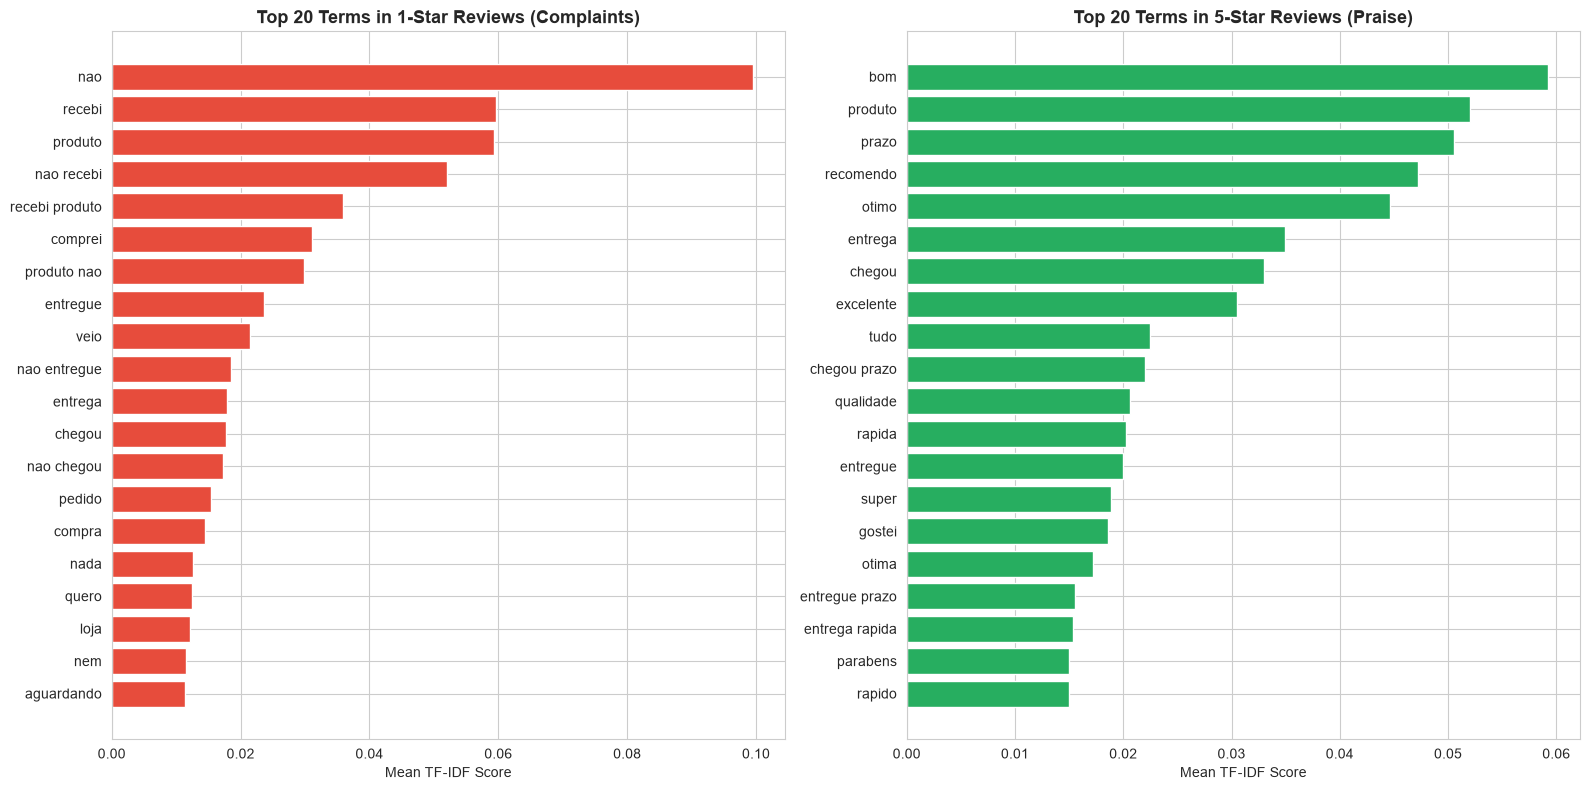

In [16]:
# ── Visualize: Top 20 terms in 1-star vs 5-star reviews ─────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# 1-star reviews (complaints)
axes[0].barh(top_1star['term'][::-1], top_1star['mean_tfidf'][::-1], color='#e74c3c')
axes[0].set_title('Top 20 Terms in 1-Star Reviews (Complaints)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean TF-IDF Score')

# 5-star reviews (praise)
axes[1].barh(top_5star['term'][::-1], top_5star['mean_tfidf'][::-1], color='#27ae60')
axes[1].set_title('Top 20 Terms in 5-Star Reviews (Praise)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean TF-IDF Score')

plt.tight_layout()
plt.show()

## A.5  Top Terms in Late vs On-Time Deliveries

Same analysis but splitting by **delivery status** instead of review score. This shows what customers complain about specifically when orders arrive late.

In [17]:
# ── Masks for late and on-time orders ───────────────────────────────
mask_late   = (review_text['is_late'] == 1).values
mask_ontime = (review_text['is_late'] == 0).values

top_late   = get_top_tfidf_terms(tfidf_matrix, feature_names, mask_late, top_n=20)
top_ontime = get_top_tfidf_terms(tfidf_matrix, feature_names, mask_ontime, top_n=20)

print(f'Late deliveries with comments:    {mask_late.sum():,}')
print(f'On-time deliveries with comments: {mask_ontime.sum():,}')

Late deliveries with comments:    4,243
On-time deliveries with comments: 34,446


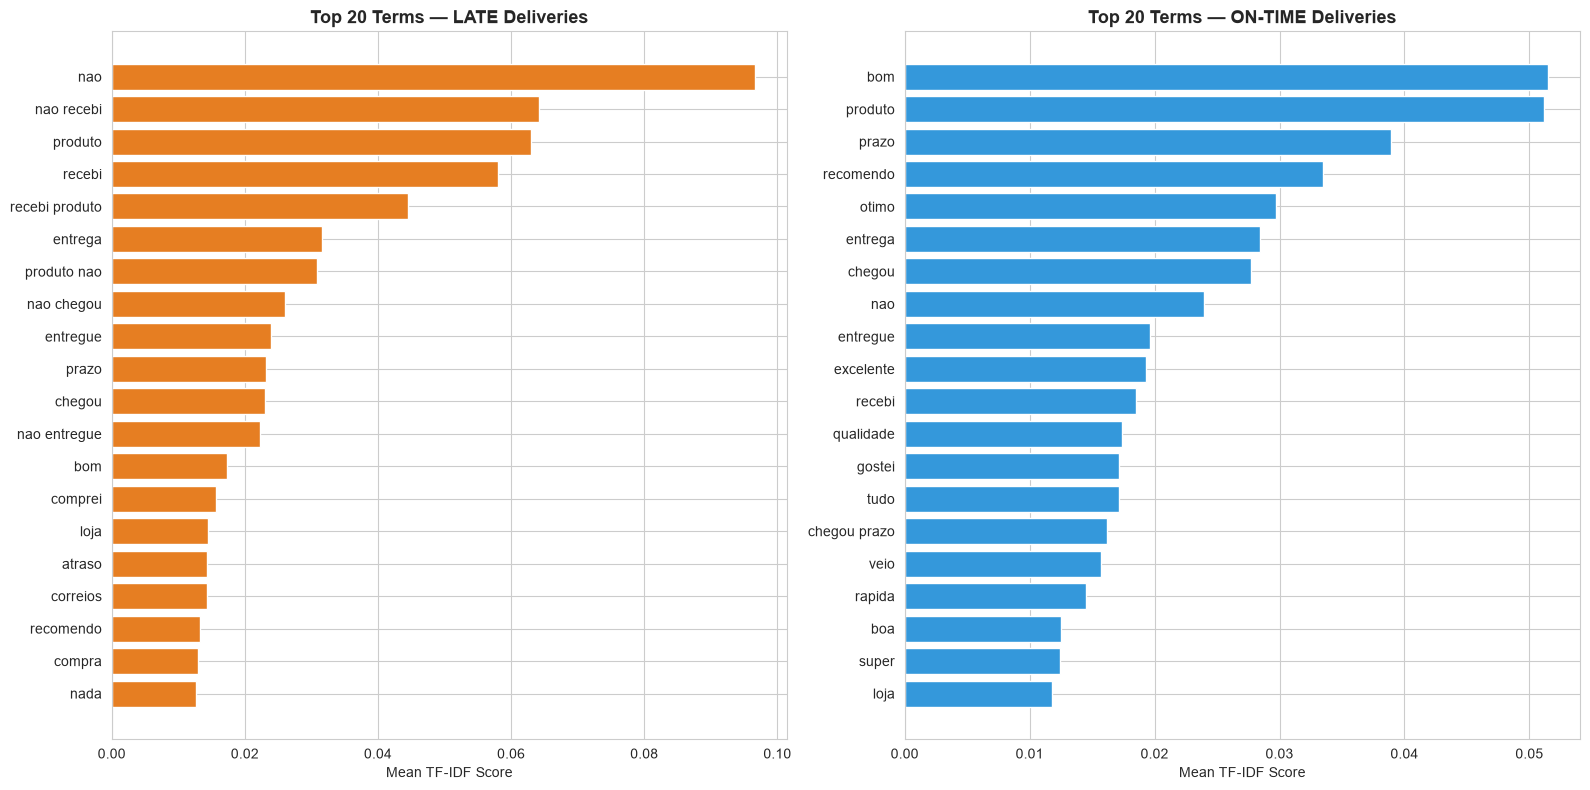

In [18]:
# ── Visualize: Late vs On-Time top terms ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(top_late['term'][::-1], top_late['mean_tfidf'][::-1], color='#e67e22')
axes[0].set_title('Top 20 Terms — LATE Deliveries', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean TF-IDF Score')

axes[1].barh(top_ontime['term'][::-1], top_ontime['mean_tfidf'][::-1], color='#3498db')
axes[1].set_title('Top 20 Terms — ON-TIME Deliveries', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Mean TF-IDF Score')

plt.tight_layout()
plt.show()

## A.6  Distinctive Terms — Difference Analysis

To find terms that are **uniquely associated** with bad reviews (not just frequent everywhere), we compute:

$$\text{distinctiveness} = \overline{\text{TF-IDF}}_{\text{1-star}} - \overline{\text{TF-IDF}}_{\text{5-star}}$$

Positive values → terms more distinctive to complaints.  
Negative values → terms more distinctive to praise.

In [19]:
# ── Compute mean TF-IDF per group for ALL terms ────────────────────
mean_1star = np.asarray(tfidf_matrix[mask_1star].mean(axis=0)).flatten()
mean_5star = np.asarray(tfidf_matrix[mask_5star].mean(axis=0)).flatten()

diff_df = pd.DataFrame({
    'term': feature_names,
    'mean_1star': mean_1star,
    'mean_5star': mean_5star,
    'difference': mean_1star - mean_5star
}).sort_values('difference', ascending=False)

# Top 15 complaint-distinctive terms
top_complaint = diff_df.head(15)
# Top 15 praise-distinctive terms
top_praise = diff_df.tail(15).sort_values('difference')

print('Top 15 terms MORE common in 1-star than 5-star:')
print(top_complaint[['term', 'difference']].to_string(index=False))
print()
print('Top 15 terms MORE common in 5-star than 1-star:')
print(top_praise[['term', 'difference']].to_string(index=False))

Top 15 terms MORE common in 1-star than 5-star:
          term  difference
           nao    0.093362
    nao recebi    0.051488
        recebi    0.049169
recebi produto    0.031491
   produto nao    0.029038
       comprei    0.027468
  nao entregue    0.018270
    nao chegou    0.016856
          veio    0.014557
        pedido    0.012273
         quero    0.012005
          nada    0.011609
    aguardando    0.011028
           nem    0.011020
        apenas    0.010455

Top 15 terms MORE common in 5-star than 1-star:
          term  difference
           bom   -0.056174
         otimo   -0.044135
     recomendo   -0.042457
         prazo   -0.040063
     excelente   -0.030115
  chegou prazo   -0.021296
          tudo   -0.020890
        rapida   -0.019920
         super   -0.017744
       entrega   -0.017123
         otima   -0.017033
        chegou   -0.015274
entrega rapida   -0.015097
      parabens   -0.014910
     qualidade   -0.014440


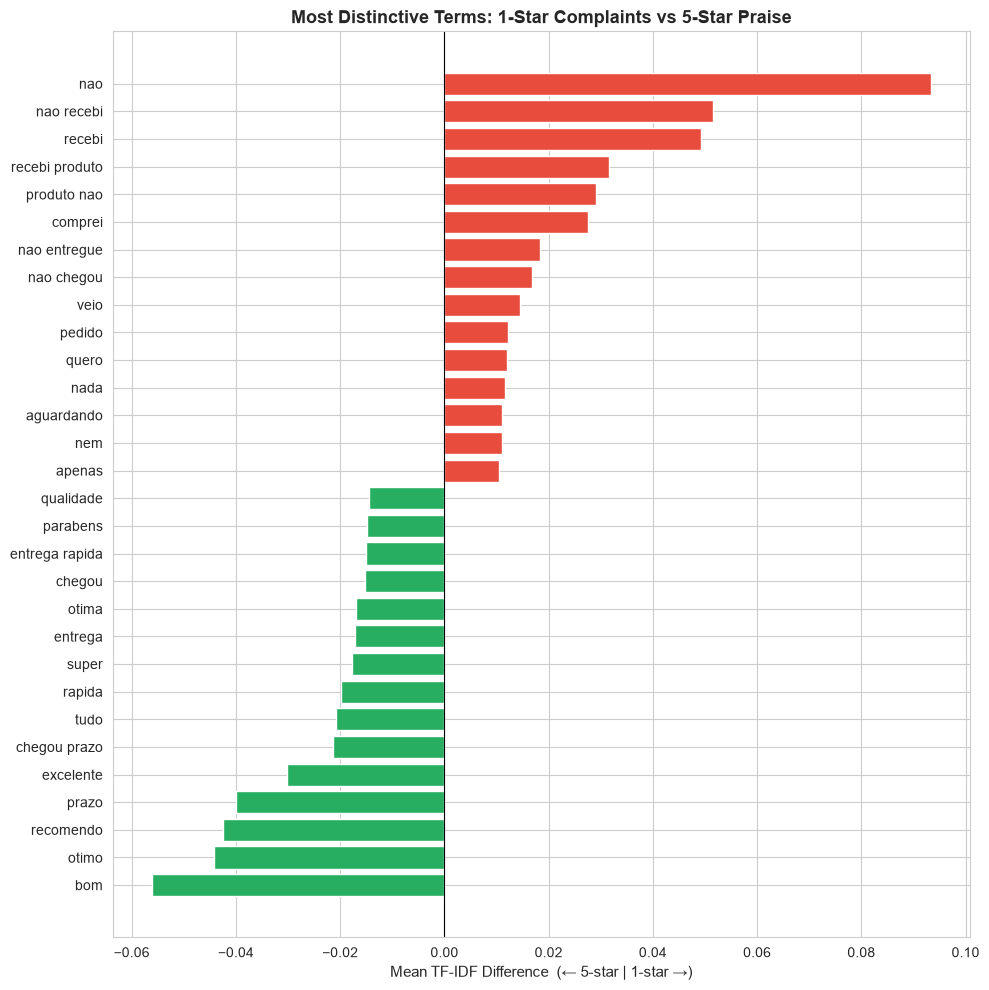

In [20]:
# ── Diverging bar chart of distinctive terms ────────────────────────
plot_df = pd.concat([
    diff_df.head(15),
    diff_df.tail(15)
]).sort_values('difference')

colors = ['#e74c3c' if d > 0 else '#27ae60' for d in plot_df['difference']]

fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(plot_df['term'], plot_df['difference'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Mean TF-IDF Difference  (← 5-star | 1-star →)', fontsize=11)
ax.set_title('Most Distinctive Terms: 1-Star Complaints vs 5-Star Praise',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## A.7  Section A Summary

| Finding | Detail |
| :--- | :--- |
| **Negation preservation** | Keeping words like `não`, `nunca`, `sem` lets us see real complaint phrases (e.g., `não recebi`, `não entregue`) instead of losing them to stopword removal. |
| **1-star distinctive terms** | Dominated by delivery-related complaints: late arrival, non-delivery, wrong product, damaged items. |
| **5-star distinctive terms** | Focus on product quality, speed, and recommendation (`recomendo`, `otimo`, `rapido`). |
| **Late vs On-time** | Late delivery reviews emphasize waiting time and contact attempts; on-time reviews focus on product satisfaction. |

---
# Section B — Shipping Network Graph Analysis

**Goal:** Model Brazil's delivery flows as a **directed, weighted network** where every node is a state and every edge `Seller State → Customer State` carries:


**Steps:** build the graph → degree / PageRank / betweenness → communities → worst routes → export.

## B.1  Build the State-to-State Edge Table

In [22]:
# Only delivered orders have a real days_late value, so the graph is built on those.
graph_df = orders.dropna(subset=['seller_state', 'customer_state', 'days_late']).copy()
graph_df['is_late'] = graph_df['is_late'].astype(float)

edges = (graph_df
         .groupby(['seller_state', 'customer_state'])
         .agg(order_count=('order_id', 'count'),
              avg_days_late=('days_late', 'mean'),
              late_rate=('is_late', 'mean'),
              avg_review=('review_score', 'mean'))
         .reset_index())

print(f'Delivered orders used for the graph : {len(graph_df):,}')
print(f'Distinct routes (edges, incl. loops): {len(edges):,}')
print(f'Seller states   : {edges["seller_state"].nunique()}')
print(f'Customer states : {edges["customer_state"].nunique()}')
edges.sort_values('order_count', ascending=False).head(10)

Delivered orders used for the graph : 96,476
Distinct routes (edges, incl. loops): 409
Seller states   : 22
Customer states : 27


,seller_state,customer_state,order_count,avg_days_late,late_rate,avg_review
407,SP,SP,30735,-9.377443,0.062209,4.246800
400,SP,RJ,8159,-10.121027,0.154921,3.887347
392,SP,MG,7441,-11.965458,0.063567,4.144055
404,SP,RS,3596,-13.486209,0.075918,4.122210
399,SP,PR,3119,-12.345452,0.053543,4.189955
276,PR,SP,2924,-14.415077,0.035568,4.273228
168,MG,SP,2546,-12.878668,0.043205,4.247927
405,SP,SC,2327,-10.265674,0.110013,4.034244
386,SP,BA,2307,-10.053958,0.149545,3.870362
153,MG,MG,1525,-11.788907,0.031475,4.361660


## B.2  Create the Directed Graph

* `G` keeps **self-loops** (e.g. `SP → SP`, orders that never leave the state) — useful for traffic statistics.
* `G_noloop` removes self-loops — used for **centrality**, because a node pointing to itself should not make it look more "central" for through-traffic.

In [23]:
G = nx.DiGraph()
for _, r in edges.iterrows():
    G.add_edge(r['seller_state'], r['customer_state'],
               order_count=int(r['order_count']),
               avg_days_late=float(r['avg_days_late']),
               late_rate=float(r['late_rate']),
               avg_review=float(r['avg_review']),
               # distance-like weight for shortest-path algorithms: busy route = short edge
               distance=1.0 / r['order_count'])

G_noloop = G.copy()
G_noloop.remove_edges_from(list(nx.selfloop_edges(G_noloop)))

print(f'Nodes (states)              : {G.number_of_nodes()}')
print(f'Edges (with self-loops)     : {G.number_of_edges()}')
print(f'Edges (without self-loops)  : {G_noloop.number_of_edges()}')
print(f'Self-loops (intra-state)    : {nx.number_of_selfloops(G)}')
print(f'Graph density (no loops)    : {nx.density(G_noloop):.3f}')
print(f'Weakly connected?           : {nx.is_weakly_connected(G_noloop)}')

Nodes (states)              : 27
Edges (with self-loops)     : 409
Edges (without self-loops)  : 392
Self-loops (intra-state)    : 17
Graph density (no loops)    : 0.558
Weakly connected?           : True


## B.3  Centrality Measures

| Metric | What it tells us here |
| :--- | :--- |
| **In-degree / Out-degree** | How many *different* states a state receives from / ships to |
| **In-strength / Out-strength** | Total **orders** received / sent (weighted degree) |
| **PageRank** (weight = `order_count`) | Importance of a state as a destination of heavy flows from important states |
| **Betweenness** (weight = `distance = 1/orders`) | How often a state lies on the "busiest-route" shortest paths between other states |

In [24]:
# ── Degree & strength (self-loops excluded) ─────────────────────────
in_deg  = dict(G_noloop.in_degree())
out_deg = dict(G_noloop.out_degree())
in_str  = dict(G_noloop.in_degree(weight='order_count'))
out_str = dict(G_noloop.out_degree(weight='order_count'))

# ── PageRank & Betweenness ──────────────────────────────────────────
pagerank    = nx.pagerank(G_noloop, alpha=0.85, weight='order_count')
betweenness = nx.betweenness_centrality(G_noloop, weight='distance', normalized=True)

# ── Intra-state share (orders that stay inside the seller's own state) ──
loop_orders = {n: G[n][n]['order_count'] if G.has_edge(n, n) else 0 for n in G.nodes}
sent_total  = {n: sum(d['order_count'] for _, _, d in G.out_edges(n, data=True)) for n in G.nodes}

node_metrics = pd.DataFrame({
    'state'        : list(G.nodes),
    'in_degree'    : [in_deg[n]  for n in G.nodes],
    'out_degree'   : [out_deg[n] for n in G.nodes],
    'in_strength'  : [in_str[n]  for n in G.nodes],
    'out_strength' : [out_str[n] for n in G.nodes],
    'pagerank'     : [pagerank[n]    for n in G.nodes],
    'betweenness'  : [betweenness[n] for n in G.nodes],
    'intra_state_share': [loop_orders[n] / sent_total[n] if sent_total[n] > 0 else np.nan for n in G.nodes],
}).set_index('state')

node_metrics.sort_values('pagerank', ascending=False).round(4).head(10)

,in_degree,out_degree,in_strength,out_strength,pagerank,betweenness,intra_state_share
state,,,,,,,
SP,20,26,9760,37682,0.2331,0.7985,0.4492
RJ,18,25,11395,3230,0.1227,0.0385,0.2287
MG,19,26,9830,6123,0.1131,0.0354,0.1994
PR,19,26,4209,6715,0.0567,0.0000,0.0961
RS,15,25,5056,1661,0.0533,0.0000,0.1478
BA,17,26,3190,483,0.0434,0.0000,0.1202
SC,16,25,3292,3296,0.0405,0.0000,0.0718
DF,16,22,2031,754,0.0314,0.0000,0.0610
ES,16,18,1988,301,0.0298,0.0000,0.0227


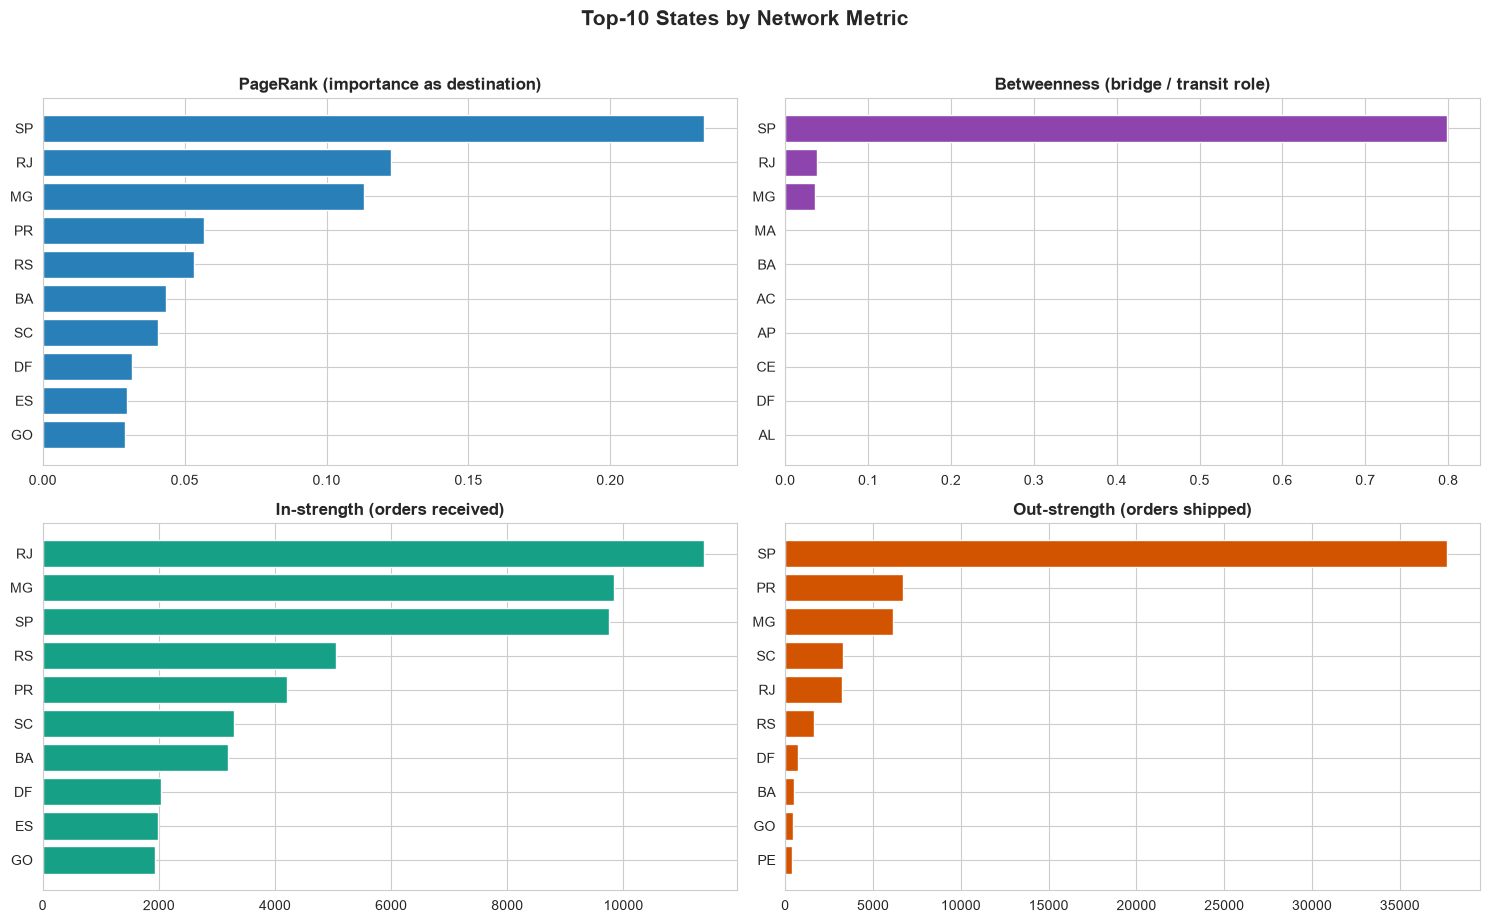

In [25]:
# ── Visualise the four main metrics (top 10 states each) ────────────
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
plots = [('pagerank',     'PageRank (importance as destination)', '#2980b9'),
         ('betweenness',  'Betweenness (bridge / transit role)',  '#8e44ad'),
         ('in_strength',  'In-strength (orders received)',        '#16a085'),
         ('out_strength', 'Out-strength (orders shipped)',        '#d35400')]

for ax, (col, title, color) in zip(axes.ravel(), plots):
    top = node_metrics[col].sort_values(ascending=False).head(10)[::-1]
    ax.barh(top.index, top.values, color=color)
    ax.set_title(title, fontsize=12, fontweight='bold')

plt.suptitle('Top-10 States by Network Metric', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## B.4  Community Detection

We treat the network as **undirected** (flow in both directions added together) and use **greedy modularity maximisation** to find groups of states that trade mostly among themselves.

In [26]:
# Undirected weighted version (sum of both directions, no self-loops)
U = nx.Graph()
for u, v, d in G_noloop.edges(data=True):
    w = d['order_count']
    if U.has_edge(u, v):
        U[u][v]['order_count'] += w
    else:
        U.add_edge(u, v, order_count=w)

communities = list(greedy_modularity_communities(U, weight='order_count'))
modularity  = nx.community.modularity(U, communities, weight='order_count')

state_to_comm = {}
for i, comm in enumerate(communities):
    for s in comm:
        state_to_comm[s] = i
node_metrics['community'] = pd.Series(state_to_comm)

print(f'Communities found : {len(communities)}')
print(f'Modularity        : {modularity:.3f}')
for i, comm in enumerate(communities):
    print(f'  Community {i}: {sorted(comm)}')

Communities found : 1
Modularity        : 0.000
  Community 0: ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


## B.5  Geographic Network Map

States are placed at approximate geographic centroids (longitude, latitude). **Node size** = PageRank, **node colour** = community, **edge width** = number of orders. Only the 60 busiest inter-state routes are drawn to keep the picture readable.

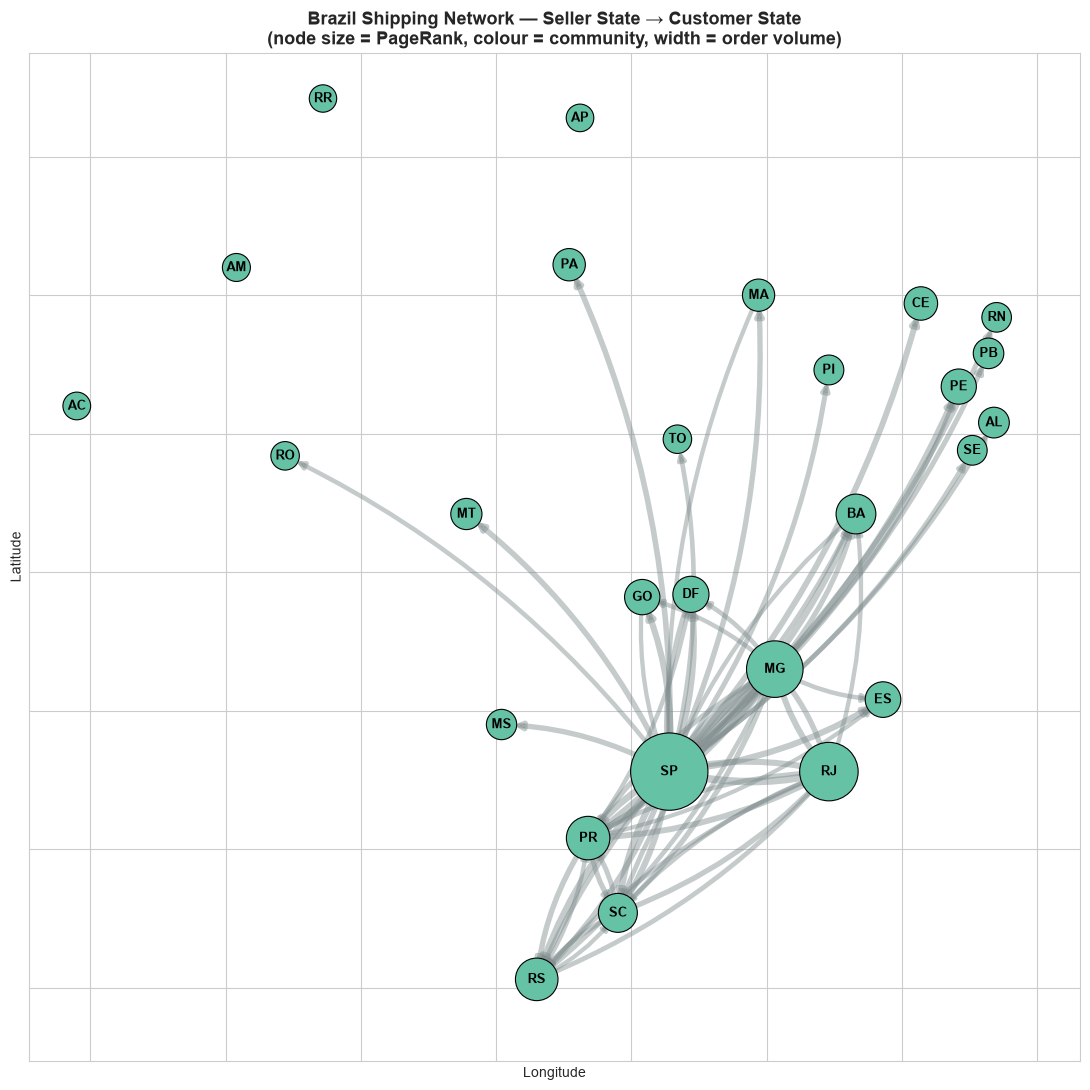

In [27]:
# Approximate state centroids (lon, lat) — used only for drawing
STATE_POS = {
    'AC': (-70.5, -9.0), 'AL': (-36.6, -9.6), 'AP': (-51.9,  1.4), 'AM': (-64.6, -4.0),
    'BA': (-41.7,-12.9), 'CE': (-39.3, -5.3), 'DF': (-47.8,-15.8), 'ES': (-40.7,-19.6),
    'GO': (-49.6,-15.9), 'MA': (-45.3, -5.0), 'MT': (-56.1,-12.9), 'MS': (-54.8,-20.5),
    'MG': (-44.7,-18.5), 'PA': (-52.3, -3.9), 'PB': (-36.8, -7.1), 'PR': (-51.6,-24.6),
    'PE': (-37.9, -8.3), 'PI': (-42.7, -7.7), 'RJ': (-42.7,-22.2), 'RN': (-36.5, -5.8),
    'RS': (-53.5,-29.7), 'RO': (-62.8,-10.8), 'RR': (-61.4,  2.1), 'SC': (-50.5,-27.3),
    'SP': (-48.6,-22.2), 'SE': (-37.4,-10.6), 'TO': (-48.3,-10.2),
}
pos = {n: STATE_POS.get(n, (0, 0)) for n in G_noloop.nodes}

top_edges = sorted(G_noloop.edges(data=True), key=lambda e: e[2]['order_count'], reverse=True)[:60]
max_w = max(e[2]['order_count'] for e in top_edges)

palette   = plt.cm.Set2.colors
node_cols = [palette[state_to_comm[n] % len(palette)] for n in G_noloop.nodes]
node_size = [300 + 12000 * pagerank[n] for n in G_noloop.nodes]

fig, ax = plt.subplots(figsize=(11, 11))
nx.draw_networkx_edges(
    G_noloop, pos, edgelist=[(u, v) for u, v, _ in top_edges],
    width=[0.4 + 5 * np.log1p(d['order_count']) / np.log1p(max_w) for _, _, d in top_edges],
    edge_color='#7f8c8d', alpha=0.45, arrows=True, arrowsize=10,
    connectionstyle='arc3,rad=0.12', ax=ax)
nx.draw_networkx_nodes(G_noloop, pos, node_color=node_cols, node_size=node_size,
                       edgecolors='black', linewidths=0.8, ax=ax)
nx.draw_networkx_labels(G_noloop, pos, font_size=9, font_weight='bold', ax=ax)

ax.set_title('Brazil Shipping Network — Seller State → Customer State\n'
             '(node size = PageRank, colour = community, width = order volume)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

## B.6  Worst Routes — Late Rate & Review Score

Rare routes (a handful of orders) can have extreme late rates by chance, so we only rank routes with at least `MIN_ORDERS` delivered orders.

Routes with ≥ 100 orders: 70 of 409


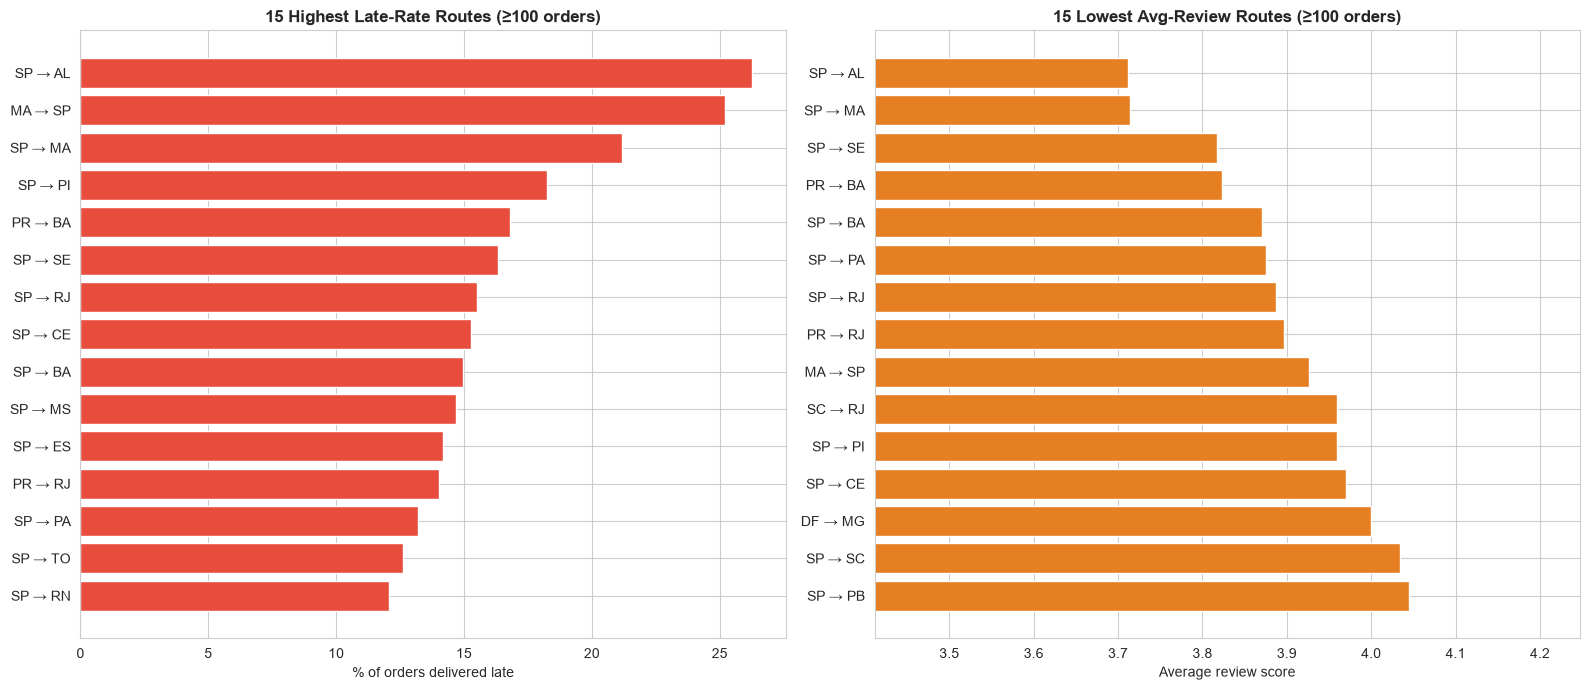

,route,order_count,late_rate,avg_days_late,avg_review
383,SP → AL,255,0.263,-7.211,3.711
141,MA → SP,123,0.252,-9.095,3.926
391,SP → MA,491,0.212,-8.608,3.715
398,SP → PI,329,0.182,-9.867,3.960
255,PR → BA,143,0.168,-9.565,3.823
406,SP → SE,208,0.163,-8.719,3.817
400,SP → RJ,8159,0.155,-10.121,3.887
387,SP → CE,969,0.153,-10.183,3.970
386,SP → BA,2307,0.150,-10.054,3.870
393,SP → MS,477,0.147,-9.480,4.075


In [28]:
MIN_ORDERS = 100     # minimum orders for a route to be ranked (change if needed)

routes = edges[edges['order_count'] >= MIN_ORDERS].copy()
routes['route'] = routes['seller_state'] + ' → ' + routes['customer_state']
print(f'Routes with ≥ {MIN_ORDERS} orders: {len(routes)} of {len(edges)}')

worst_late   = routes.sort_values('late_rate', ascending=False).head(15)
worst_review = routes.sort_values('avg_review').head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(worst_late['route'][::-1], worst_late['late_rate'][::-1] * 100, color='#e74c3c')
axes[0].set_title(f'15 Highest Late-Rate Routes (≥{MIN_ORDERS} orders)', fontweight='bold')
axes[0].set_xlabel('% of orders delivered late')

axes[1].barh(worst_review['route'][::-1], worst_review['avg_review'][::-1], color='#e67e22')
axes[1].set_title(f'15 Lowest Avg-Review Routes (≥{MIN_ORDERS} orders)', fontweight='bold')
axes[1].set_xlabel('Average review score')
axes[1].set_xlim(left=max(1, worst_review['avg_review'].min() - 0.3))

plt.tight_layout()
plt.show()

worst_late[['route', 'order_count', 'late_rate', 'avg_days_late', 'avg_review']].round(3)

In [29]:
# ── High-VOLUME problem routes: where late deliveries hurt the most orders ──
routes['late_orders'] = (routes['late_rate'] * routes['order_count']).round().astype(int)
biggest_pain = routes.sort_values('late_orders', ascending=False).head(10)
print('Routes producing the largest NUMBER of late orders:')
biggest_pain[['route', 'order_count', 'late_orders', 'late_rate', 'avg_review']].round(3)

Routes producing the largest NUMBER of late orders:


,route,order_count,late_orders,late_rate,avg_review
407,SP → SP,30735,1912,0.062,4.247
400,SP → RJ,8159,1264,0.155,3.887
392,SP → MG,7441,473,0.064,4.144
386,SP → BA,2307,345,0.150,3.870
404,SP → RS,3596,273,0.076,4.122
405,SP → SC,2327,256,0.110,4.034
389,SP → ES,1461,207,0.142,4.047
399,SP → PR,3119,167,0.054,4.190
387,SP → CE,969,148,0.153,3.970
269,PR → RJ,963,135,0.140,3.897


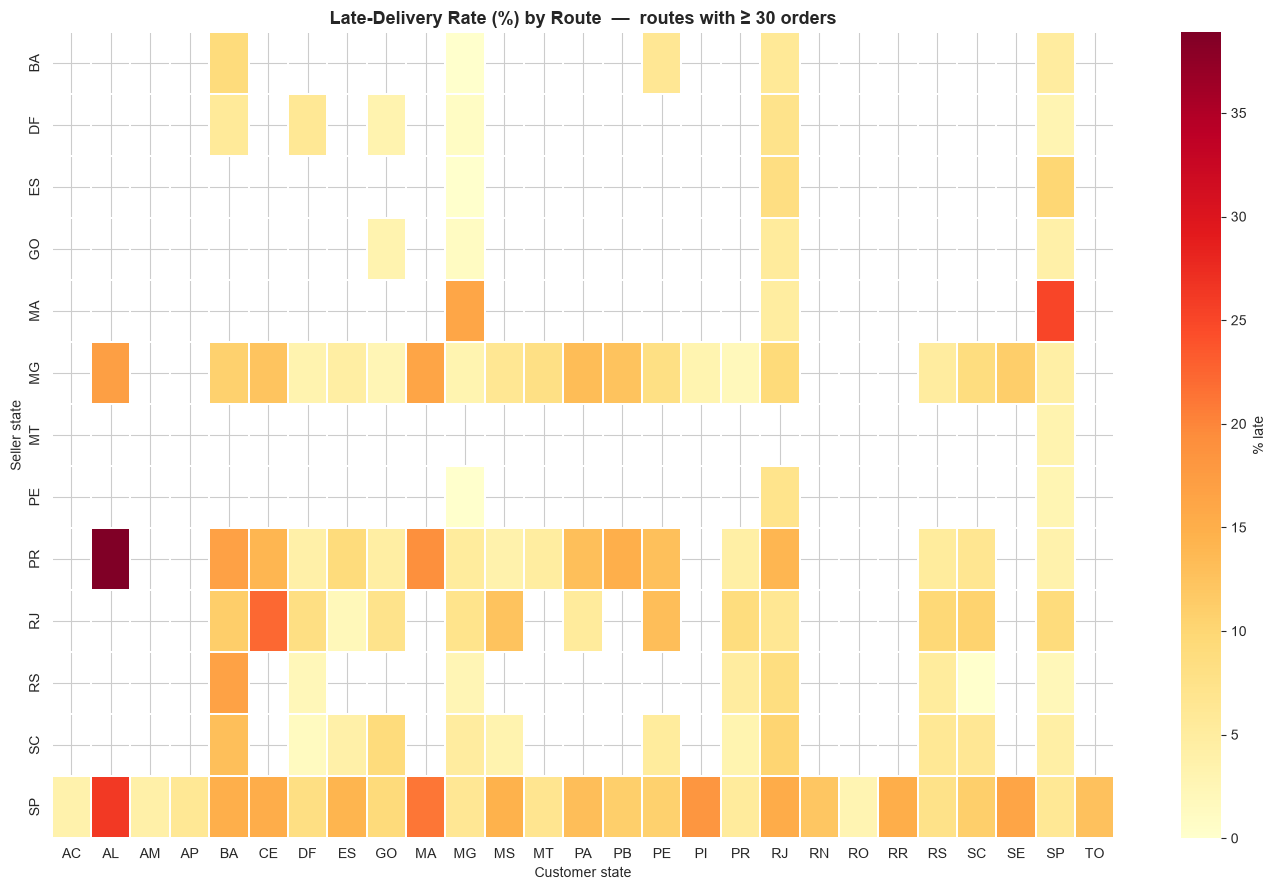

In [30]:
# ── Heatmap: late rate for every seller-state × customer-state pair ─
HEAT_MIN = 30
heat = (edges[edges['order_count'] >= HEAT_MIN]
        .pivot(index='seller_state', columns='customer_state', values='late_rate') * 100)

plt.figure(figsize=(14, 9))
sns.heatmap(heat, cmap='YlOrRd', linewidths=0.3, linecolor='white',
            cbar_kws={'label': '% late'}, annot=False)
plt.title(f'Late-Delivery Rate (%) by Route  —  routes with ≥ {HEAT_MIN} orders', fontsize=13, fontweight='bold')
plt.xlabel('Customer state'); plt.ylabel('Seller state')
plt.tight_layout()
plt.show()

## B.7  Same-State vs Cross-State Shipping, and State-Level Performance

             orders  late_rate  mean_days_late  avg_review
route_type                                                
Cross state   61773      0.093         -12.045       4.095
Same state    34703      0.061          -9.637       4.263


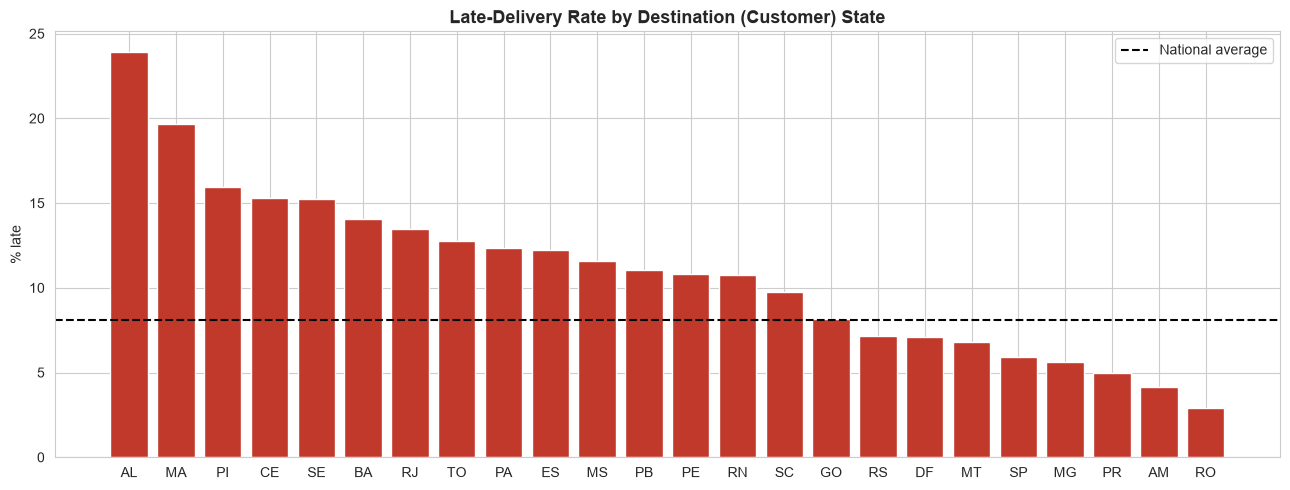

In [31]:
# ── Same-state vs cross-state ───────────────────────────────────────
graph_df['route_type'] = np.where(graph_df['seller_state'] == graph_df['customer_state'],
                                  'Same state', 'Cross state')
route_type_summary = (graph_df.groupby('route_type')
                      .agg(orders=('order_id', 'count'),
                           late_rate=('is_late', 'mean'),
                           mean_days_late=('days_late', 'mean'),
                           avg_review=('review_score', 'mean'))
                      .round(3))
print(route_type_summary)

# ── Worst destination states (customer side) ────────────────────────
dest_perf = (graph_df.groupby('customer_state')
             .agg(orders=('order_id', 'count'),
                  late_rate=('is_late', 'mean'),
                  avg_review=('review_score', 'mean'))
             .query('orders >= 100')
             .sort_values('late_rate', ascending=False))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(dest_perf.index, dest_perf['late_rate'] * 100, color='#c0392b')
ax.axhline(graph_df['is_late'].mean() * 100, color='black', ls='--', label='National average')
ax.set_title('Late-Delivery Rate by Destination (Customer) State', fontsize=13, fontweight='bold')
ax.set_ylabel('% late'); ax.legend()
plt.tight_layout()
plt.show()

# Merge late-rate / review of each state (as destination) into node metrics
node_metrics = node_metrics.join(dest_perf[['late_rate', 'avg_review']]
                                 .rename(columns={'late_rate': 'dest_late_rate',
                                                  'avg_review': 'dest_avg_review'}))

## B.8  Section B Summary

The cell below prints the main network findings automatically from the computed results, so the numbers always match the data.

In [32]:
top_pr   = node_metrics['pagerank'].idxmax()
top_bw   = node_metrics['betweenness'].idxmax()
top_out  = node_metrics['out_strength'].idxmax()
top_in   = node_metrics['in_strength'].idxmax()
share_sp = node_metrics.loc[top_out, 'out_strength'] / node_metrics['out_strength'].sum() * 100
w = worst_late.iloc[0]

print('════════ SECTION B — KEY FINDINGS ════════')
print(f'• Network: {G.number_of_nodes()} states, {G_noloop.number_of_edges()} inter-state routes, '
      f'{len(communities)} communities (modularity {modularity:.2f}).')
print(f'• Largest shipper (out-strength): {top_out}  → {share_sp:.1f}% of all inter-state orders originate there.')
print(f'• Largest receiver (in-strength): {top_in};  highest PageRank: {top_pr};  highest betweenness: {top_bw}.')
print(f'• Worst high-volume-filtered route by late rate: {w["route"]}  '
      f'({w["late_rate"]*100:.1f}% late, {int(w["order_count"])} orders, avg review {w["avg_review"]:.2f}).')
same  = route_type_summary.loc['Same state']
cross = route_type_summary.loc['Cross state']
print(f'• Late rate: same-state {same["late_rate"]*100:.1f}%  vs  cross-state {cross["late_rate"]*100:.1f}%.')
print(f'• Review score: same-state {same["avg_review"]:.2f}  vs  cross-state {cross["avg_review"]:.2f}.')

════════ SECTION B — KEY FINDINGS ════════
• Network: 27 states, 392 inter-state routes, 1 communities (modularity 0.00).
• Largest shipper (out-strength): SP  → 61.0% of all inter-state orders originate there.
• Largest receiver (in-strength): RJ;  highest PageRank: SP;  highest betweenness: SP.
• Worst high-volume-filtered route by late rate: SP → AL  (26.3% late, 255 orders, avg review 3.71).
• Late rate: same-state 6.1%  vs  cross-state 9.3%.
• Review score: same-state 4.26  vs  cross-state 4.09.


---
# Section C — Association Rule Mining (Lecture 18)

Two mining tasks, both with **FP-Growth** (and an Apriori comparison):

1. **Category co-purchases** — which product categories appear together in the same multi-item order?
2. **Order risk profiles** — which combinations of route, category, freight, distance and delay lead to a **low review score (1–2 stars)**?

### Metrics recap

| Metric | Formula | Reading |
| :--- | :--- | :--- |
| Support | P(A ∩ B) | How common the pattern is |
| Confidence | P(B \| A) | How often B follows when A is present |
| Lift | P(B \| A) / P(B) | > 1 → A makes B more likely than normal |
| Leverage | P(A ∩ B) − P(A)P(B) | Absolute gain over independence |
| Conviction | (1 − P(B)) / (1 − conf) | How strongly the rule is "violated" by chance |

In [34]:
# Helper functions used by both mining tasks ─────────────────────────
def pick_col(df, candidates, contains=None):
    # Return the first existing column from candidates, else the first column containing a keyword.
    for c in candidates:
        if c in df.columns:
            return c
    if contains:
        for c in df.columns:
            if contains.lower() in c.lower():
                return c
    return None

def make_rules(freq_items, n_rows, **kwargs):
    # association_rules() changed its signature across mlxtend versions.
    try:
        return association_rules(freq_items, num_itemsets=n_rows, **kwargs)
    except TypeError:
        return association_rules(freq_items, **kwargs)

def fs_to_str(fs):
    return ' + '.join(sorted(fs))

CAT_COL     = pick_col(items,  ['product_category_name_english', 'category_english',
                                'product_category_english', 'product_category_name'], contains='categor')
FREIGHT_COL = pick_col(orders, ['total_freight', 'freight_value', 'order_freight', 'freight'], contains='freight')
PRICE_COL   = pick_col(orders, ['total_price', 'order_price', 'price', 'total_items_price'], contains='price')

print('Category column (items)  :', CAT_COL)
print('Freight column (orders)  :', FREIGHT_COL)
print('Price column (orders)    :', PRICE_COL)

Category column (items)  : product_category_name_english
Freight column (orders)  : total_freight
Price column (orders)    : total_price


## C.1  Category Co-Purchases (Market-Basket Analysis)

Each **basket** = the set of distinct product categories in one order. Most Olist orders contain a single item, so we first check how many baskets are actually usable.

In [35]:
items_cat = items.dropna(subset=[CAT_COL]).copy()

baskets = (items_cat.groupby('order_id')[CAT_COL]
           .apply(lambda s: sorted(set(s)))
           .reset_index(name='categories'))
baskets['n_cat'] = baskets['categories'].str.len()

print(f'Orders with a known category      : {len(baskets):,}')
print(f'Orders with ≥ 2 distinct categories: {(baskets["n_cat"] >= 2).sum():,} '
      f'({(baskets["n_cat"] >= 2).mean()*100:.1f}%)')
print()
print('Distinct categories per order:')
print(baskets['n_cat'].value_counts().sort_index().head(8))

Orders with a known category      : 98,666
Orders with ≥ 2 distinct categories: 786 (0.8%)

Distinct categories per order:
n_cat
1    97880
2      768
3       18
Name: count, dtype: int64


In [36]:
multi = baskets[baskets['n_cat'] >= 2].reset_index(drop=True)
n_multi = len(multi)

# ── 1) Simple, exact pair counts (the baskets are tiny, so this is reliable) ──
from itertools import combinations
from collections import Counter

pair_counts = Counter()
for cats in multi['categories']:
    for a, b in combinations(cats, 2):
        pair_counts[(a, b)] += 1

cat_counts = Counter(c for cats in baskets['categories'] for c in cats)   # across ALL orders
n_all = len(baskets)

pair_df = pd.DataFrame([{'cat_a': a, 'cat_b': b, 'orders_together': n,
                         'lift_all_orders': (n / n_all) / ((cat_counts[a] / n_all) * (cat_counts[b] / n_all))}
                        for (a, b), n in pair_counts.items()])
pair_df = pair_df.sort_values('orders_together', ascending=False)

print(f'Distinct category pairs seen together: {len(pair_df):,}')
pair_df.head(15).round(2)

Distinct category pairs seen together: 262


,cat_a,cat_b,orders_together,lift_all_orders
22,bed_bath_table,furniture_decor,70,0.11
86,bed_bath_table,home_confort,43,1.13
28,furniture_decor,housewares,24,0.06
3,bed_bath_table,housewares,20,0.04
9,baby,cool_stuff,20,0.19
1,baby,toys,19,0.17
45,furniture_decor,garden_tools,17,0.07
47,baby,bed_bath_table,17,0.06
78,health_beauty,sports_leisure,14,0.02
38,housewares,unknown,14,0.16


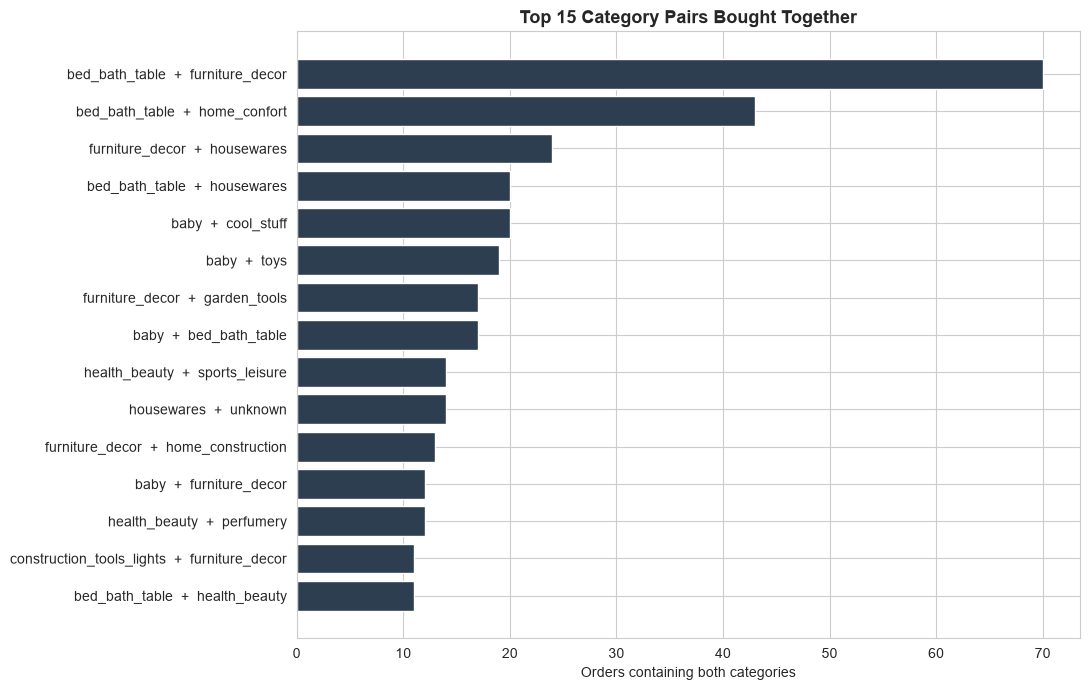

In [37]:
# ── Bar chart of the 15 most frequent category pairs ────────────────
top_pairs = pair_df.head(15).copy()
top_pairs['pair'] = top_pairs['cat_a'] + '  +  ' + top_pairs['cat_b']

plt.figure(figsize=(11, 7))
plt.barh(top_pairs['pair'][::-1], top_pairs['orders_together'][::-1], color='#2c3e50')
plt.xlabel('Orders containing both categories')
plt.title('Top 15 Category Pairs Bought Together', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [38]:
# ── 2) FP-Growth on the multi-category baskets ─────────────────────
te = TransactionEncoder()
basket_matrix = pd.DataFrame(te.fit(multi['categories']).transform(multi['categories']),
                             columns=[str(c) for c in te.columns_])   # plain str (avoids np.str_ issues in mlxtend)

MIN_SUP_CAT = max(0.002, 15 / n_multi)         # at least ~15 baskets
freq_cat = fpgrowth(basket_matrix, min_support=MIN_SUP_CAT, use_colnames=True)
print(f'Frequent itemsets (support ≥ {MIN_SUP_CAT:.4f}): {len(freq_cat):,}')

rules_cat = make_rules(freq_cat, n_multi, metric='lift', min_threshold=1.0)
rules_cat = rules_cat[(rules_cat['antecedents'].apply(len) == 1) &
                      (rules_cat['consequents'].apply(len) == 1)].copy()
rules_cat['antecedent']  = rules_cat['antecedents'].apply(fs_to_str)
rules_cat['consequent']  = rules_cat['consequents'].apply(fs_to_str)
rules_cat['n_baskets']   = (rules_cat['support'] * n_multi).round().astype(int)

rules_cat = rules_cat.sort_values(['lift', 'n_baskets'], ascending=False)
print(f'Category rules (lift ≥ 1): {len(rules_cat):,}')
rules_cat[['antecedent', 'consequent', 'n_baskets', 'support', 'confidence', 'lift']].head(15).round(3)

Frequent itemsets (support ≥ 0.0191): 34
Category rules (lift ≥ 1): 8


,antecedent,consequent,n_baskets,support,confidence,lift
6,bed_bath_table,home_confort,43,0.055,0.211,3.314
7,home_confort,bed_bath_table,43,0.055,0.860,3.314
0,baby,toys,19,0.024,0.204,3.149
1,toys,baby,19,0.024,0.373,3.149
4,baby,cool_stuff,20,0.025,0.215,2.523
5,cool_stuff,baby,20,0.025,0.299,2.523
2,furniture_decor,bed_bath_table,70,0.089,0.340,1.309
3,bed_bath_table,furniture_decor,70,0.089,0.343,1.309


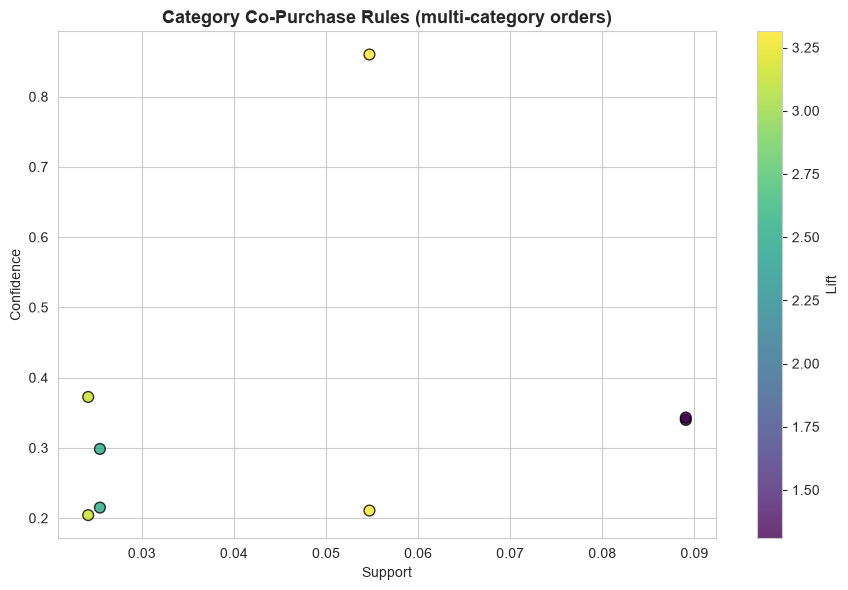

In [39]:
# ── Support vs Confidence scatter coloured by lift ──────────────────
if len(rules_cat) > 0:
    plt.figure(figsize=(9, 6))
    sc = plt.scatter(rules_cat['support'], rules_cat['confidence'],
                     c=rules_cat['lift'], cmap='viridis', s=60, alpha=0.8, edgecolors='k')
    plt.colorbar(sc, label='Lift')
    plt.xlabel('Support'); plt.ylabel('Confidence')
    plt.title('Category Co-Purchase Rules (multi-category orders)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('No category rules at this support threshold — lower MIN_SUP_CAT.')

## C.2  Order Risk Profiles → Low Review Score

Because ~97% of Olist orders contain a single item, category baskets are small. The more useful question for DELTA is:

> **Which combinations of route, category, freight, distance and delay carry a high risk of a 1–2 star review?**

Each order becomes a **transaction of tags**:

| Tag family | Values |
| :--- | :--- |
| `Seller_State=` | SP, RJ, MG … |
| `Customer_Region=` | North, Northeast, Central-West, Southeast, South |
| `Route=` | Same_State / Cross_State |
| `Status=` | On_Time_or_Early, Late_1_3d, Late_4_7d, Late_gt_7d |
| `Freight=` | High (top 25 % freight-to-price ratio) / Normal |
| `Distance=` | Long (top 25 %) / Short_Medium |
| `Handling=` | Slow (seller handling > 3 days) / Normal |
| `Category=` | 15 most common categories (main = highest-priced item) |
| **Target** | `Low_Review_Score` = review ≤ 2 |

In [40]:
REGION = {
    'AC': 'North', 'AP': 'North', 'AM': 'North', 'PA': 'North', 'RO': 'North', 'RR': 'North', 'TO': 'North',
    'AL': 'Northeast', 'BA': 'Northeast', 'CE': 'Northeast', 'MA': 'Northeast', 'PB': 'Northeast',
    'PE': 'Northeast', 'PI': 'Northeast', 'RN': 'Northeast', 'SE': 'Northeast',
    'DF': 'Central-West', 'GO': 'Central-West', 'MT': 'Central-West', 'MS': 'Central-West',
    'ES': 'Southeast', 'MG': 'Southeast', 'RJ': 'Southeast', 'SP': 'Southeast',
    'PR': 'South', 'RS': 'South', 'SC': 'South',
}

# Delivered orders that have a review score
risk = orders.dropna(subset=['seller_state', 'customer_state', 'days_late', 'review_score']).copy()

tags = pd.DataFrame(index=risk.index)
tags['Seller_State']     = risk['seller_state']
tags['Customer_Region']  = risk['customer_state'].map(REGION)
tags['Route']            = np.where(risk['seller_state'] == risk['customer_state'], 'Same_State', 'Cross_State')
tags['Status']           = pd.cut(risk['days_late'], bins=[-np.inf, 0, 3, 7, np.inf],
                                  labels=['On_Time_or_Early', 'Late_1_3d', 'Late_4_7d', 'Late_gt_7d'])

# Freight burden = freight / price (only if both columns exist)
if FREIGHT_COL and PRICE_COL:
    ratio = risk[FREIGHT_COL] / risk[PRICE_COL].replace(0, np.nan)
    tags['Freight'] = np.where(ratio >= ratio.quantile(0.75), 'High', 'Normal')
    tags.loc[ratio.isna(), 'Freight'] = np.nan

if 'distance_km' in risk.columns:
    d = risk['distance_km']
    tags['Distance'] = np.where(d >= d.quantile(0.75), 'Long', 'Short_Medium')
    tags.loc[d.isna(), 'Distance'] = np.nan

if 'seller_handling_days' in risk.columns:
    h = risk['seller_handling_days']
    tags['Handling'] = np.where(h > 3, 'Slow', 'Normal')
    tags.loc[h.isna(), 'Handling'] = np.nan

# Main category = category of the highest-priced item in the order
main_cat = (items_cat.sort_values('price', ascending=False)
            .drop_duplicates('order_id')
            .set_index('order_id')[CAT_COL])
risk_cat = risk['order_id'].map(main_cat)
top15 = risk_cat.value_counts().head(15).index
tags['Category'] = risk_cat.where(risk_cat.isin(top15))

target = (risk['review_score'] <= 2)

print(f'Orders in the risk table: {len(tags):,}')
print(f'Base rate of Low_Review_Score: {target.mean()*100:.2f}%')
tags.head()

Orders in the risk table: 95,830
Base rate of Low_Review_Score: 12.81%


,Seller_State,Customer_Region,Route,Status,Freight,Distance,Handling,Category
0,SP,Southeast,Same_State,On_Time_or_Early,Normal,Short_Medium,Normal,housewares
1,SP,Northeast,Cross_State,On_Time_or_Early,Normal,Long,Normal,perfumery
2,SP,Central-West,Cross_State,On_Time_or_Early,Normal,Short_Medium,Normal,auto
3,MG,Northeast,Cross_State,On_Time_or_Early,High,Long,Slow,NaN
4,SP,Southeast,Same_State,On_Time_or_Early,High,Short_Medium,Normal,NaN


In [41]:
# ── One-hot encode the tags: one boolean column per "Family=Value" ───
onehot = pd.get_dummies(tags, prefix_sep='=', dtype=bool)
onehot['Low_Review_Score'] = target.values

print(f'One-hot matrix: {onehot.shape[0]:,} transactions × {onehot.shape[1]} items')
print('Sample columns:', list(onehot.columns[:8]))

One-hot matrix: 95,830 transactions × 55 items
Sample columns: ['Seller_State=AM', 'Seller_State=BA', 'Seller_State=CE', 'Seller_State=DF', 'Seller_State=ES', 'Seller_State=GO', 'Seller_State=MA', 'Seller_State=MG']


In [42]:
import time

MIN_SUP_RISK = 0.005       # pattern must appear in ≥ 0.5 % of orders
MAX_LEN      = 4           # keep rules readable (≤ 3 conditions → 1 outcome)

# ── FP-Growth vs Apriori: same answer, different speed ─────────────
t0 = time.time()
freq_fp = fpgrowth(onehot, min_support=MIN_SUP_RISK, use_colnames=True, max_len=MAX_LEN)
t_fp = time.time() - t0

t0 = time.time()
freq_ap = apriori(onehot, min_support=MIN_SUP_RISK, use_colnames=True, max_len=MAX_LEN)
t_ap = time.time() - t0

print(f'FP-Growth : {len(freq_fp):>6,} itemsets in {t_fp:6.2f}s')
print(f'Apriori   : {len(freq_ap):>6,} itemsets in {t_ap:6.2f}s')
print(f'Same itemsets found? {len(freq_fp) == len(freq_ap)}')

FP-Growth :  4,272 itemsets in   1.54s
Apriori   :  4,272 itemsets in   3.14s
Same itemsets found? True


In [43]:
# ── Generate rules and keep only those predicting Low_Review_Score ──
n_tx = len(onehot)
rules_all = make_rules(freq_fp, n_tx, metric='confidence', min_threshold=0.10)

is_risk_rule = rules_all['consequents'].apply(lambda c: c == frozenset({'Low_Review_Score'}))
rules_risk = rules_all[is_risk_rule].copy()

rules_risk['antecedent'] = rules_risk['antecedents'].apply(fs_to_str)
rules_risk['n_orders']   = (rules_risk['support'] * n_tx).round().astype(int)
rules_risk['has_delay']  = rules_risk['antecedents'].apply(lambda a: any(x.startswith('Status=Late') for x in a))

base_rate = target.mean()
print(f'Rules with consequent = Low_Review_Score: {len(rules_risk):,}')
print(f'Base rate (any order): {base_rate*100:.1f}%  →  lift 1.0 = no better than average')

cols = ['antecedent', 'n_orders', 'support', 'confidence', 'lift', 'leverage', 'conviction']
top_risk = rules_risk.sort_values('lift', ascending=False)
top_risk[cols].head(15).round(3)

Rules with consequent = Low_Review_Score: 341
Base rate (any order): 12.8%  →  lift 1.0 = no better than average


,antecedent,n_orders,support,confidence,lift,leverage,conviction
16750,Customer_Region=Southeast + Route=Cross_State ...,1131,0.012,0.806,6.293,0.010,4.497
16650,Distance=Short_Medium + Route=Cross_State + St...,1194,0.012,0.806,6.290,0.010,4.487
16796,Handling=Slow + Route=Cross_State + Status=Lat...,1067,0.011,0.805,6.282,0.009,4.464
16891,Customer_Region=Southeast + Handling=Slow + St...,818,0.009,0.804,6.279,0.007,4.456
16979,Freight=High + Seller_State=SP + Status=Late_g...,535,0.006,0.803,6.271,0.005,4.433
16860,Distance=Short_Medium + Handling=Slow + Status...,843,0.009,0.801,6.250,0.007,4.372
16556,Route=Cross_State + Seller_State=SP + Status=L...,1570,0.016,0.799,6.234,0.014,4.329
16822,Freight=Normal + Handling=Slow + Status=Late_g...,997,0.010,0.798,6.227,0.009,4.308
16775,Handling=Slow + Status=Late_gt_7d,1319,0.014,0.797,6.222,0.012,4.295
16963,Freight=High + Route=Cross_State + Status=Late...,625,0.007,0.796,6.216,0.005,4.278


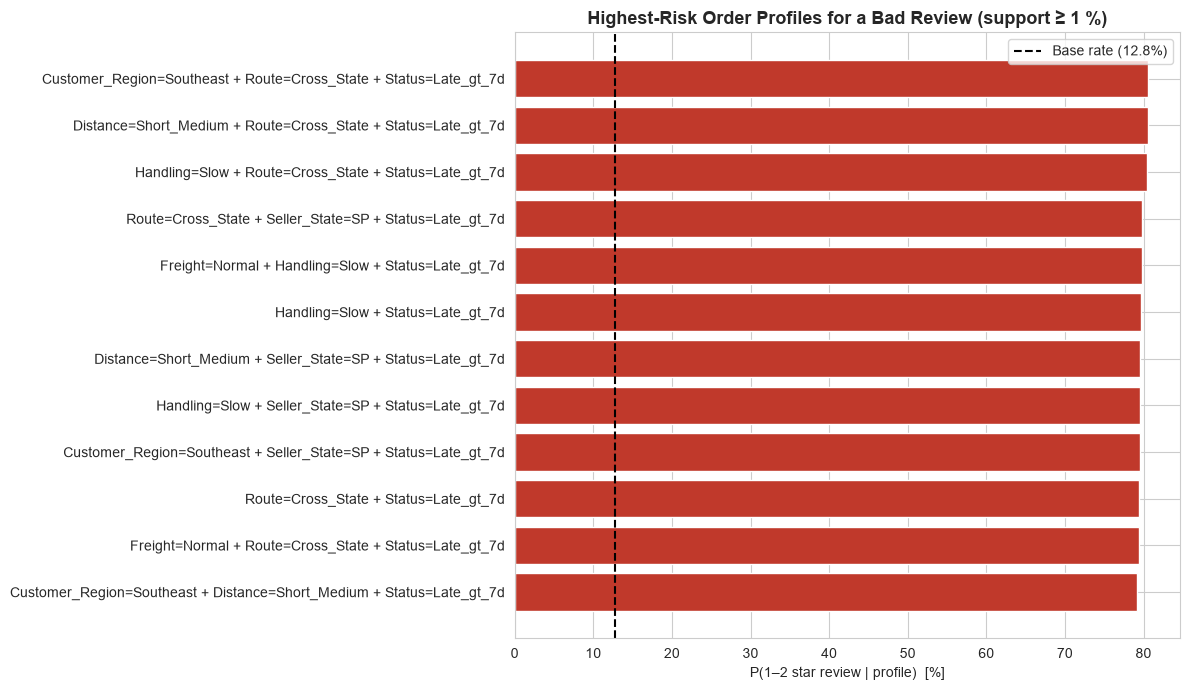

In [44]:
# ── Top-12 riskiest profiles (min 1 % support so they are not tiny niches) ──
solid = (rules_risk[rules_risk['support'] >= 0.01]
         .sort_values('lift', ascending=False).head(12))

plt.figure(figsize=(12, 7))
bars = plt.barh(solid['antecedent'][::-1], solid['confidence'][::-1] * 100, color='#c0392b')
plt.axvline(base_rate * 100, color='black', ls='--', label=f'Base rate ({base_rate*100:.1f}%)')
plt.xlabel('P(1–2 star review | profile)  [%]')
plt.title('Highest-Risk Order Profiles for a Bad Review (support ≥ 1 %)', fontsize=13, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

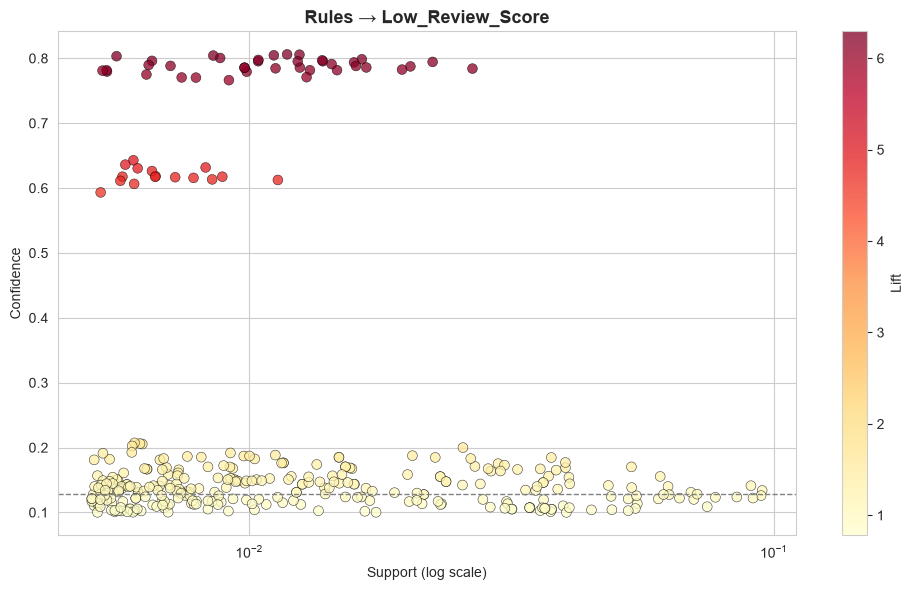

In [45]:
# ── Support vs Confidence landscape ─────────────────────────────────
plt.figure(figsize=(10, 6))
sc = plt.scatter(rules_risk['support'], rules_risk['confidence'],
                 c=rules_risk['lift'], cmap='YlOrRd', s=50, alpha=0.75, edgecolors='k', linewidths=0.4)
plt.colorbar(sc, label='Lift')
plt.axhline(base_rate, color='grey', ls='--', lw=1)
plt.xscale('log')
plt.xlabel('Support (log scale)'); plt.ylabel('Confidence')
plt.title('Rules → Low_Review_Score', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### C.3  Does Risk Exist *Without* Delay?

Late delivery is the obvious driver. The more interesting question for the marketplace is: **which profiles are risky even when no delay tag is present?** Those point to product, freight or route problems that cannot be fixed by better delivery estimates alone.

In [46]:
no_delay = (rules_risk[(~rules_risk['has_delay']) & (rules_risk['support'] >= 0.005)]
            .sort_values('lift', ascending=False))

print('Riskiest profiles that do NOT include a "Late" tag:')
no_delay[cols].head(12).round(3)

Riskiest profiles that do NOT include a "Late" tag:


,antecedent,n_orders,support,confidence,lift,leverage,conviction
3303,Customer_Region=Northeast + Distance=Long + Ha...,579,0.006,0.207,1.618,0.002,1.100
3297,Customer_Region=Northeast + Handling=Slow + Ro...,593,0.006,0.206,1.609,0.002,1.098
3179,Customer_Region=Northeast + Handling=Slow,599,0.006,0.205,1.604,0.002,1.097
13633,Category=bed_bath_table + Handling=Slow,573,0.006,0.202,1.581,0.002,1.093
8912,Handling=Slow + Route=Cross_State + Seller_Sta...,2447,0.026,0.200,1.561,0.009,1.090
13787,Category=bed_bath_table + Customer_Region=Sout...,572,0.006,0.193,1.504,0.002,1.080
8297,Distance=Long + Handling=Slow + Seller_State=SP,882,0.009,0.192,1.497,0.003,1.079
8455,Freight=High + Handling=Slow + Route=Cross_State,1074,0.011,0.188,1.471,0.004,1.074
8893,Customer_Region=Southeast + Handling=Slow + Ro...,1960,0.020,0.188,1.464,0.006,1.073
13629,Category=bed_bath_table + Route=Cross_State,959,0.010,0.187,1.460,0.003,1.072


                  orders  low_review_rate  lift_vs_base
Status                                                 
On_Time_or_Early   88168            0.092         0.720
Late_1_3d           2636            0.191         1.493
Late_4_7d           1773            0.613         4.782
Late_gt_7d          3253            0.784         6.122


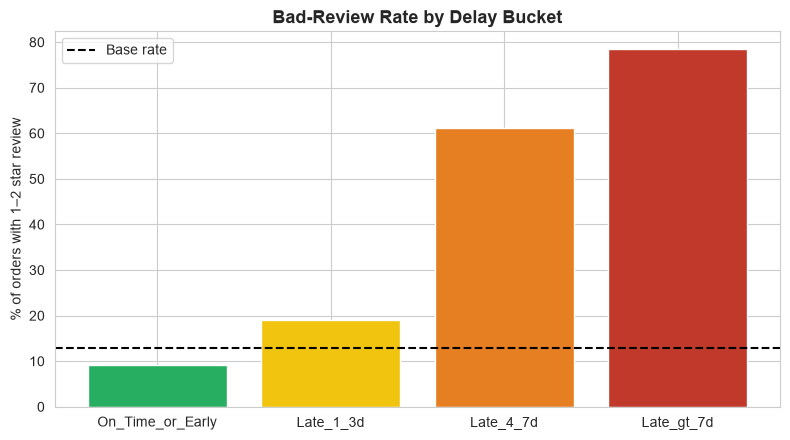

In [47]:
# ── Effect of the delay tag on its own (sanity check vs rules) ──────
delay_effect = (pd.DataFrame({'Status': tags['Status'], 'low': target})
                .groupby('Status', observed=True)['low']
                .agg(orders='count', low_review_rate='mean'))
delay_effect['lift_vs_base'] = delay_effect['low_review_rate'] / base_rate
print(delay_effect.round(3))

plt.figure(figsize=(8, 4.5))
plt.bar(delay_effect.index.astype(str), delay_effect['low_review_rate'] * 100,
        color=['#27ae60', '#f1c40f', '#e67e22', '#c0392b'])
plt.axhline(base_rate * 100, color='black', ls='--', label='Base rate')
plt.ylabel('% of orders with 1–2 star review'); plt.legend()
plt.title('Bad-Review Rate by Delay Bucket', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## C.4  Section C Summary

In [48]:
best = top_risk[top_risk['support'] >= 0.01].iloc[0]
print('════════ SECTION C — KEY FINDINGS ════════')
print(f'• {n_multi:,} orders ({n_multi/len(baskets)*100:.1f}%) have ≥ 2 categories; '
      f'most common pair: {pair_df.iloc[0]["cat_a"]} + {pair_df.iloc[0]["cat_b"]} '
      f'({int(pair_df.iloc[0]["orders_together"])} orders).')
print(f'• FP-Growth and Apriori agree ({len(freq_fp):,} itemsets); timings: FP-Growth {t_fp:.2f}s vs Apriori {t_ap:.2f}s.')
print(f'• Base rate of 1–2 star reviews: {base_rate*100:.1f}%.')
print(f'• Strongest profile with support ≥ 1%: [{best["antecedent"]}]')
print(f'    → {best["confidence"]*100:.1f}% bad reviews  (lift {best["lift"]:.2f}, {int(best["n_orders"])} orders).')
gt7 = delay_effect.loc['Late_gt_7d']
print(f'• Orders more than 7 days late: {gt7["low_review_rate"]*100:.1f}% get 1–2 stars '
      f'({gt7["lift_vs_base"]:.1f}× the base rate).')

════════ SECTION C — KEY FINDINGS ════════
• 786 orders (0.8%) have ≥ 2 categories; most common pair: bed_bath_table + furniture_decor (70 orders).
• FP-Growth and Apriori agree (4,272 itemsets); timings: FP-Growth 1.54s vs Apriori 3.14s.
• Base rate of 1–2 star reviews: 12.8%.
• Strongest profile with support ≥ 1%: [Customer_Region=Southeast + Route=Cross_State + Status=Late_gt_7d]
    → 80.6% bad reviews  (lift 6.29, 1131 orders).
• Orders more than 7 days late: 78.4% get 1–2 stars (6.1× the base rate).


---
# Export Outputs for the Dashboard

Saves every result needed by `app.py` into `PROCESSED_DATA/` (same folder as Notebook 01's outputs).

In [49]:
# ── Section A outputs ───────────────────────────────────────────────
diff_df.to_csv(os.path.join(DATA_DIR, 'nlp_distinctive_terms.csv'), index=False)

top_terms_all = pd.concat([
    top_1star.assign(group='1-star'),   top_5star.assign(group='5-star'),
    top_late.assign(group='late'),      top_ontime.assign(group='on-time')
])
top_terms_all.to_csv(os.path.join(DATA_DIR, 'nlp_top_terms.csv'), index=False)

# ── Section B outputs ───────────────────────────────────────────────
node_metrics.reset_index().to_csv(os.path.join(DATA_DIR, 'graph_state_metrics.csv'), index=False)
edges.to_csv(os.path.join(DATA_DIR, 'graph_route_performance.csv'), index=False)

# ── Section C outputs ───────────────────────────────────────────────
pair_df.to_csv(os.path.join(DATA_DIR, 'rules_category_pairs.csv'), index=False)
rules_cat[['antecedent', 'consequent', 'n_baskets', 'support', 'confidence', 'lift']] \
    .to_csv(os.path.join(DATA_DIR, 'rules_category_copurchase.csv'), index=False)
rules_risk[cols].sort_values('lift', ascending=False) \
    .to_csv(os.path.join(DATA_DIR, 'rules_bad_review_risk.csv'), index=False)

saved = ['nlp_distinctive_terms.csv', 'nlp_top_terms.csv', 'graph_state_metrics.csv',
         'graph_route_performance.csv', 'rules_category_pairs.csv',
         'rules_category_copurchase.csv', 'rules_bad_review_risk.csv']
print('Saved to PROCESSED_DATA/:')
for f in saved:
    print('  ✓', f)

Saved to PROCESSED_DATA/:
  ✓ nlp_distinctive_terms.csv
  ✓ nlp_top_terms.csv
  ✓ graph_state_metrics.csv
  ✓ graph_route_performance.csv
  ✓ rules_category_pairs.csv
  ✓ rules_category_copurchase.csv
  ✓ rules_bad_review_risk.csv


---
# Notebook 04 — Final Conclusions (answering the project questions)

| Project question | What Notebook 04 contributes |
| :--- | :--- |
| **Q3 — Which routes / seller groups are worst?** | Section B ranks every `Seller State → Customer State` route by late rate, avg review and number of late orders; the heatmap, destination-state bar chart and map show which states get the slowest deliveries, and the network metrics show how much traffic depends on a few hub states (read the exact states/numbers from the Section B summary output). |
| **Q4 — What do customers complain about besides delays?** | Section A shows, with negation words kept, that the top 1-star phrases are non-delivery ones (`não recebi`, `não entregue`, `não chegou`), while 5-star praise centres on quality (`bom`, `otimo`, `recomendo`) and on-time arrival (`chegou prazo`). |
| **Q2 — How much delay do customers tolerate?** | Section C shows the bad-review rate climbing with each delay bucket, and the rules show which route/category/freight combinations are risky even **without** a delay. |

**Hand-off to Member 5 / Streamlit:** the seven CSV files saved above can be read directly by `app.py` for the *Text*, *Network* and *Rules* tabs.